# 07 — ClimateSense Multimodal Attention Fusion Network (MAF-Net)
**Branches.** Climate (A), air quality (B) and dryness proxy (C) sequences are encoded by separate
temporal encoders $E_m$; static context (D) by an MLP. Each representation is projected to a
common space and tagged with a learned modality embedding:

$$z_m = \mathrm{LN}(W_m E_m(X_{:,\mathcal F_m})) + e_m,\qquad m\in\{A,B,C,D\}.$$

**Masked modality attention.** Optional self-attention among the tokens, then a learned query $q$
pools them with multi-head cross-attention; modalities missing for the whole window are removed
through the key-padding mask $\mathcal M$ (never replaced by fictitious values):

$$\alpha = \mathrm{softmax}\Big(\frac{qW_Q (ZW_K)^\top}{\sqrt{d}} + \mathcal M\Big),\qquad f=\alpha ZW_V W_O .$$

**Gated residual.** $g=\sigma(W_g[f;\bar z])$, $u = g\odot f + (1-g)\odot\bar z$ with $\bar z$ the masked
mean of tokens; head: LN → Linear → GELU → Dropout → Linear(4) → softmax.

**Modality dropout** (enhancement) randomly masks whole modalities during training so the model
does not over-rely on one branch and degrades gracefully when a modality is missing.
The `fusion="concat"` variant replaces attention with concatenation (ablation).

In [1]:
import sys, json, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib
import matplotlib.pyplot as plt
from IPython.display import Image, display, Markdown
pd.set_option("display.max_columns", 60); pd.set_option("display.width", 220)
from climatesense.utils import read_json
import platform, torch, sklearn
print("Executed:", pd.Timestamp.now().strftime("%Y-%m-%d %H:%M"), "| Python", platform.python_version(),
      "| torch", torch.__version__, "| sklearn", sklearn.__version__, "| pandas", pd.__version__)
def show(p, width=850):
    display(Image(filename=str(ROOT / p), width=width))

Executed: 2026-10-25 18:06 | Python 3.13.7 | torch 2.14.1+cu126 | sklearn 1.9.1 | pandas 3.1.0


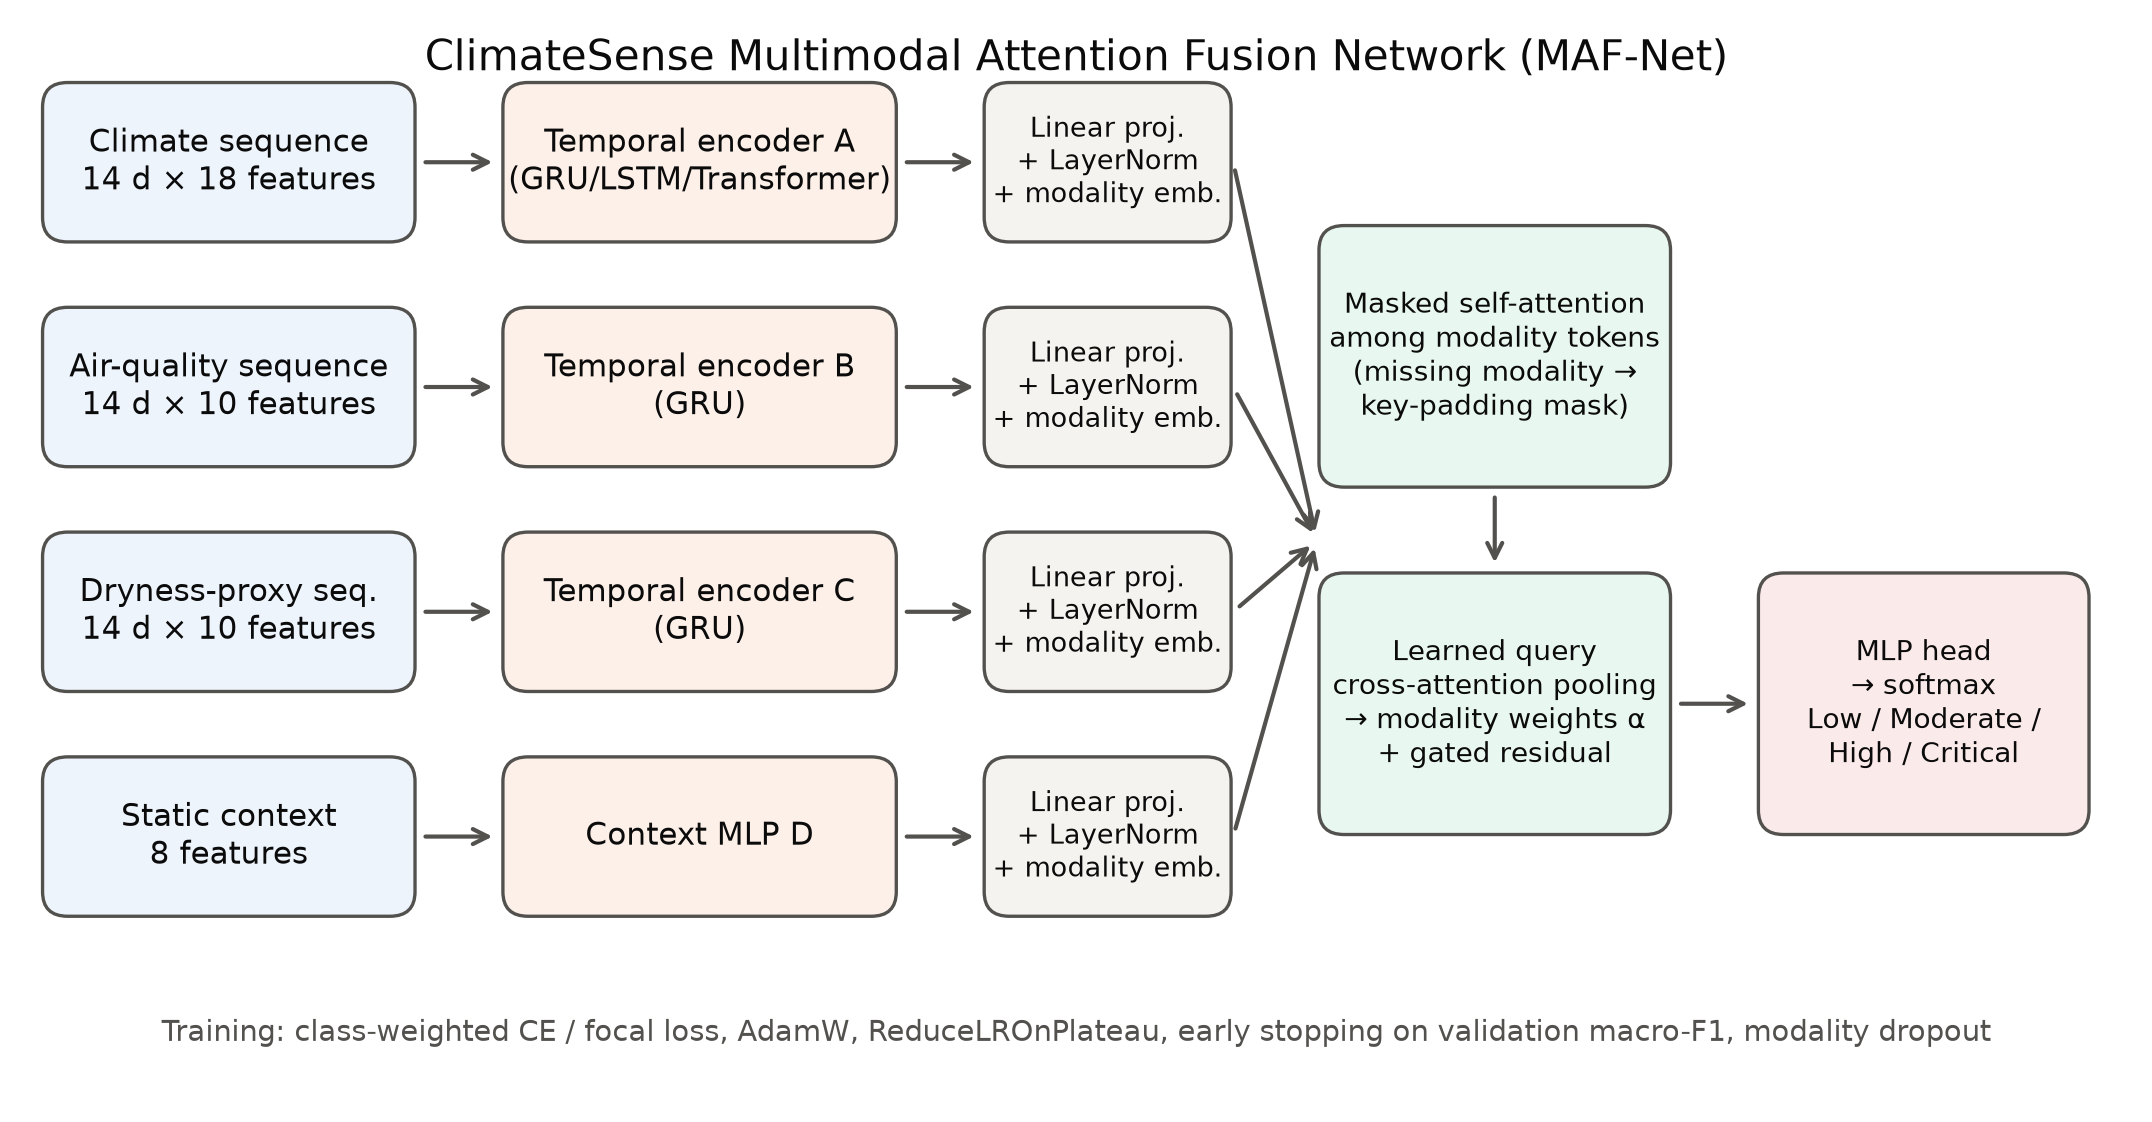

In [2]:
show("results/figures/architecture_mafnet.png", 900)

In [3]:
from climatesense.training.trainer import get_arrays, build_model_on_cols, DEFAULTS, feature_sets
sel = read_json(ROOT / "experiments/tuning/selected_configs.json")["mafnet"]
cfg = {**DEFAULTS, **sel["params"], "model": "mafnet"}
print("selected hyper-parameters (validation macro-F1 = %.4f):" % sel["val_macro_f1"]); print(json.dumps(sel["params"], indent=1))
arr = get_arrays()
model, cols = build_model_on_cols(cfg, arr)
fs = feature_sets(cfg, arr)
print({m: len(v) for m, v in fs.items()}, "| total trainable parameters:", f"{sum(p.numel() for p in model.parameters()):,}")
print(model)

selected hyper-parameters (validation macro-F1 = 0.7455):
{
 "hidden": 32,
 "layers": 1,
 "dropout": 0.3,
 "lr": 0.001,
 "batch_size": 256,
 "weight_decay": 0.0,
 "loss": "focal",
 "encoder": "transformer",
 "d_model": 32,
 "heads": 2,
 "modality_dropout": 0.0,
 "token_self_attention": true
}


{'climate': 18, 'air': 10, 'dryness': 10} | total trainable parameters: 33,268
MAFNet(
  (encoders): ModuleDict(
    (climate): TemporalEncoder(
      (inp): Linear(in_features=18, out_features=32, bias=True)
      (pos): PositionalEncoding()
      (net): TransformerEncoder(
        (layers): ModuleList(
          (0): TransformerEncoderLayer(
            (self_attn): MultiheadAttention(
              (out_proj): NonDynamicallyQuantizableLinear(in_features=32, out_features=32, bias=True)
            )
            (linear1): Linear(in_features=32, out_features=64, bias=True)
            (dropout): Dropout(p=0.3, inplace=False)
            (linear2): Linear(in_features=64, out_features=32, bias=True)
            (norm1): LayerNorm((32,), eps=1e-05, elementwise_affine=True, bias=True)
            (norm2): LayerNorm((32,), eps=1e-05, elementwise_affine=True, bias=True)
            (dropout1): Dropout(p=0.3, inplace=False)
            (dropout2): Dropout(p=0.3, inplace=False)
          )
  

### Tensor shapes through the network (forward hooks on a real batch)

In [4]:
import torch
from climatesense.training.trainer import WindowBatcher
b = WindowBatcher(arr, cfg, cols); model.eval()
idx = torch.as_tensor(arr.sample_index(cfg["lookback"], 1, "val")[:32])
x, c, y = b.get(idx.to(b.X.device)); model.to(b.X.device)
shapes = []
for name, mod in list(model.encoders.items()):
    mod.register_forward_hook(lambda m, i, o, n=name: shapes.append((f"encoder[{n}]", tuple(i[0].shape), tuple(o.shape))))
model.ctx_enc.register_forward_hook(lambda m, i, o: shapes.append(("context MLP", tuple(i[0].shape), tuple(o.shape))))
model.cross.register_forward_hook(lambda m, i, o: shapes.append(("cross-attention", tuple(i[1].shape), tuple(o[0].shape))))
model.head.register_forward_hook(lambda m, i, o: shapes.append(("classifier head", tuple(i[0].shape), tuple(o.shape))))
with torch.no_grad(): logits, w = model(x, c)
display(pd.DataFrame(shapes, columns=["module", "input shape", "output shape"]))
print("attention weights per sample:", tuple(w.shape), "rows sum to", w.sum(1)[:3].cpu().numpy())

,module,input shape,output shape
0,encoder[climate],"(32, 14, 18)","(32, 32)"
1,encoder[air],"(32, 14, 10)","(32, 16)"
2,encoder[dryness],"(32, 14, 10)","(32, 16)"
3,context MLP,"(32, 8)","(32, 32)"
4,cross-attention,"(32, 4, 32)","(32, 1, 32)"
5,classifier head,"(32, 32)","(32, 4)"


attention weights per sample: (32, 4) rows sum to [1. 1. 1.]


### Selected run: training dynamics

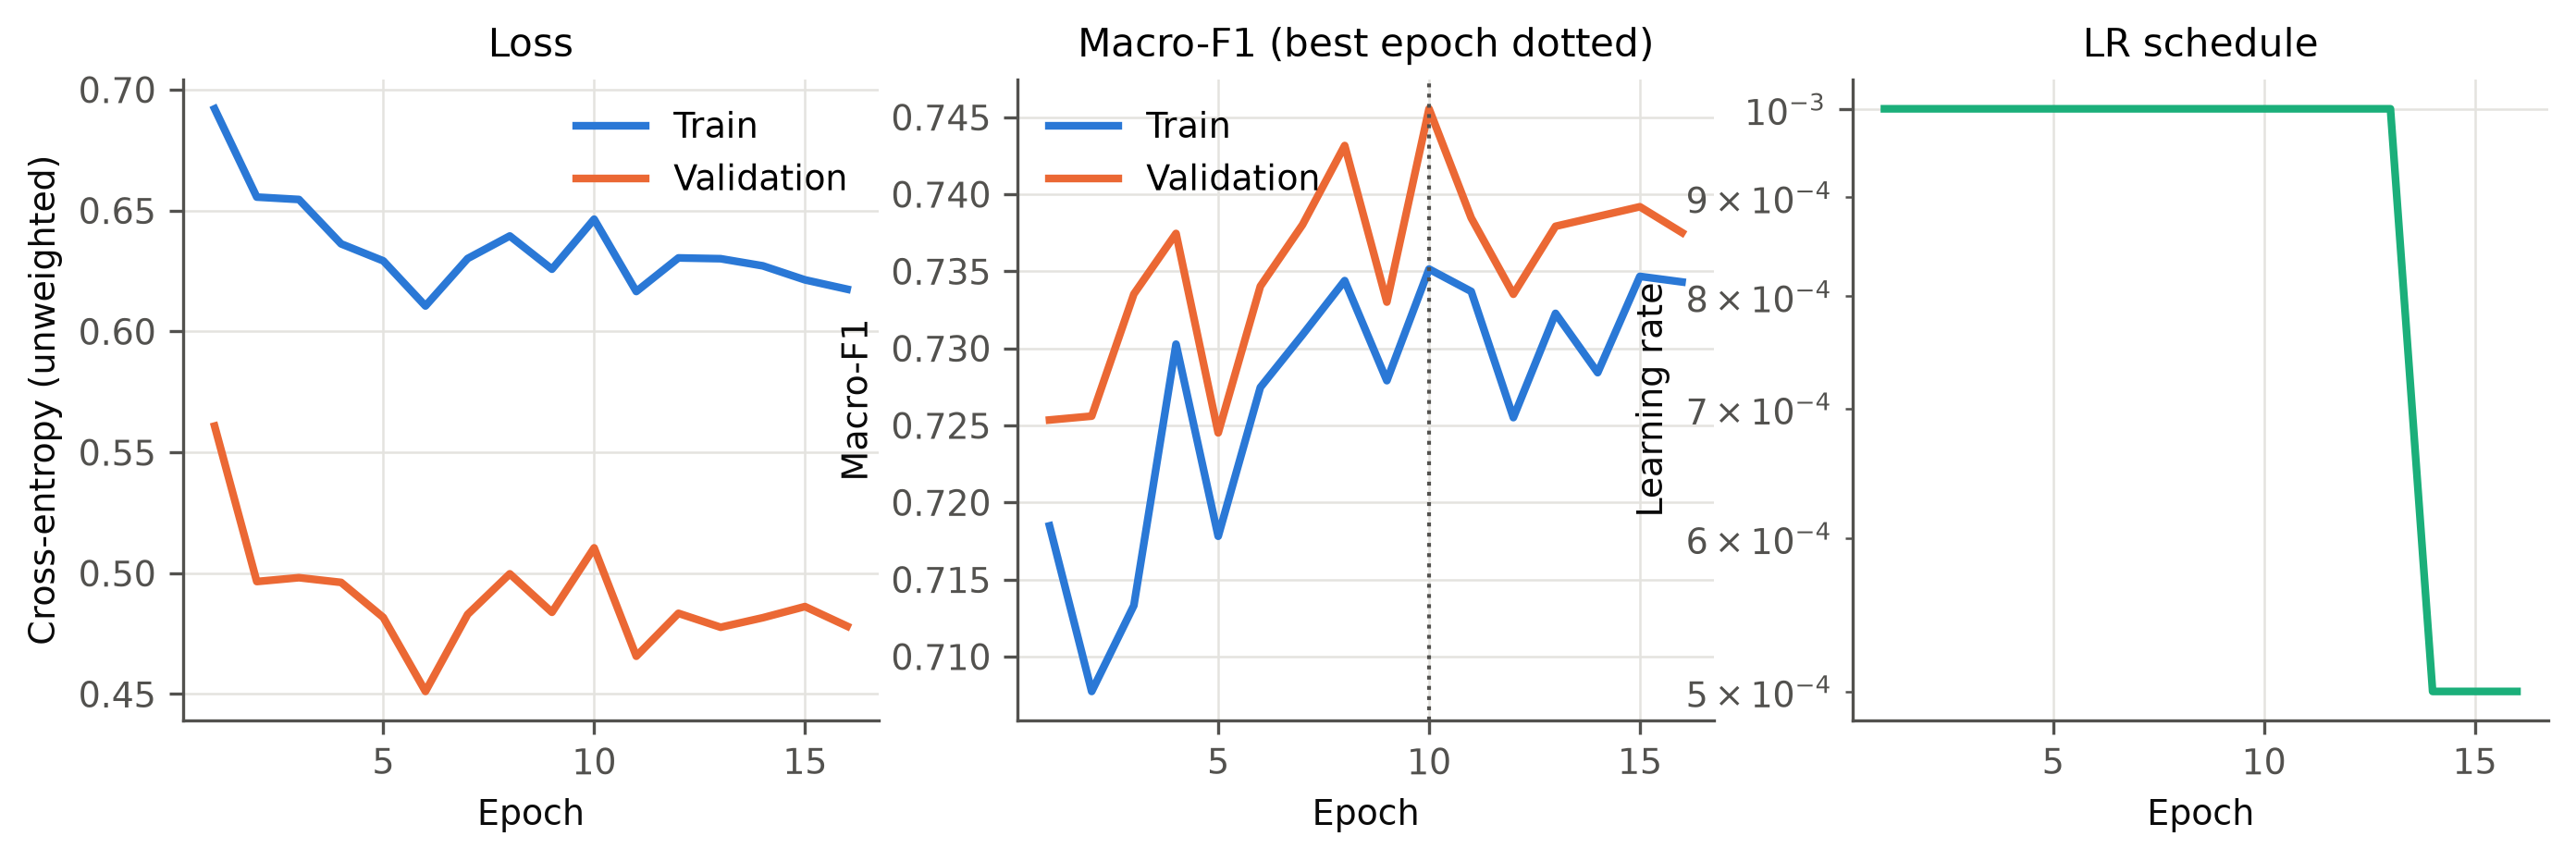

In [5]:
show("results/figures/training_curves.png")

The attention weights above are produced by an actual attention operation over modality
tokens; they indicate how the fusion module weighted the representations, **not** causal
importance (see notebook 10).